## Exercício

Considere $X \sim \mathrm{Binomial}(n,p)$.

1. Implemente a simulação de $X$ pelo método ingênuo, escrevendo $X$ como soma de $n$ variáveis aleatórias independentes com distribuição $\mathrm{Bernoulli}(p)$.

2. Implemente o método recursivo visto em sala:

   * Gere $U \sim U(0,1)$.

   * Inicialize $i=0$, $p_i=(1-p)^n$ e $F=p_i$.

   * Enquanto $U>F$, faça

     $$
     p_{i+1}=
     \frac{n-i}{i+1}
     \frac{p}{1-p}
     p_i,
     $$

     e atualize $i \leftarrow i+1$ e $F \leftarrow F+p_i$.

   * Retorne $X=i$.

3. Use a função `np.linspace` para reproduzir os passos anteriores para diferentes valores de $p$, compare o tempo de execução dos dois métodos. Para cada valor de $p$, execute cada método 100 vezes e calcule a média dos tempos. Utilize `time.time()` para medir o tempo de execução de cada método.

4. Apresente os resultados em uma tabela ou gráfico e comente como o tempo de execução dos métodos varia com $p$.


(array([ 1.,  4., 14., 15., 18., 14., 14., 13.,  5.,  2.]),
 array([20. , 22.1, 24.2, 26.3, 28.4, 30.5, 32.6, 34.7, 36.8, 38.9, 41. ]),
 <BarContainer object of 10 artists>)

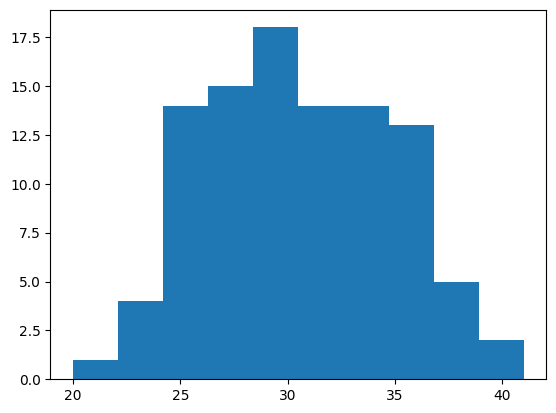

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

#Item 1
N= 100
p =0.3

amostra =[]

for i in range(N):
  uniforme = np.random.uniform(size=100)
  binomial = np.sum(uniforme <= p)
  amostra.append(binomial)



plt.hist(amostra)






In [ ]:
#Item 2
n = 100
p = 0.3
N = 10000
uniforme = np.random.uniform(0, 1)
i = 0
pi = (1-p)**n
F = pi
X = []
while uniforme > F:
  pi = ((n-i)/(i+1))*(p)/(1-p)*pi
  i = i +1
  F = F + pi


print(i)








29


In [ ]:
#Item 2
import time

tempos_p = []
n = 100
vals_p = np.linspace(0.01, 0.99, 100)
for p in vals_p:
  N = 100
  inicio = time.time()
  for i in range(N):
    uniforme = np.random.uniform(0, 1)
    i = 0
    pi = (1-p)**n
    F = pi
    X = []
    while uniforme > F:
      pi = ((n-i)/(i+1))*(p)/(1-p)*pi
      i = i +1
      F = F + pi
  fim = time.time()
  tempo = fim - inicio
  tempos_p.append(tempo)

media_tempos = np.mean(tempos_p)
print(media_tempos)



0.003989758491516113


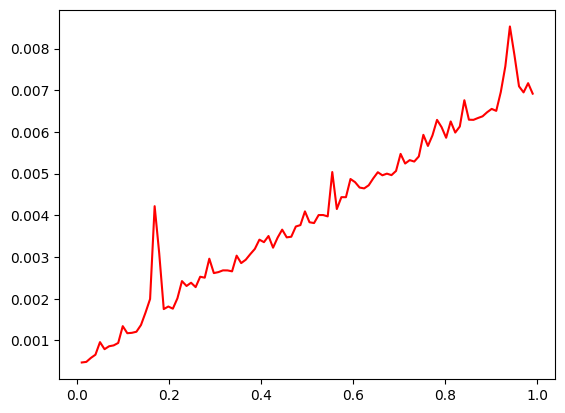

In [ ]:
#Item 4

plt.plot(vals_p, tempos_p, color="Red")


Nota-se que, quanto maior for o p, o tempo de duração do experimento também tende a ser maior